In [1]:
# Only in Colab: work inside the homework folder of Drive (the .py files are there)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir("/content/drive/MyDrive/POSGRADOS/HUNGRIA/MASTER/1/FNANCIAL PROCESS /HOMEWORKS/2_HW_LECTURE_4")
except ImportError:
    pass
print(os.getcwd())

/home/claude/hw2task/final


**Homework 2: Implement calibrator for Tree. Part 2: Task. Q3: Demo B, one-step tree for several contracts**

*Demonstrate the calibrate method for various input parameters ([...]; calibrate one step tree for various contracts (different expiries and strike levels, flat interest rate)). Make simple plots to illustrate results.*

Contracts: $S_0 = 1$, $T \in \{0.25, 0.5, 1, 2\}$, $K \in \{0.8, 0.9, 1.0, 1.1, 1.2\}$, yearly $DF = 0.95$. Same code as `demo_B.py`; here the plots are shown, not saved to `figures/`.

**Code of Q1 and of the earlier homeworks**, imported from the `.py` files of this folder: `calibrator.py` (Q1, `2_HW_EXE_2`), `bg_functions.py` (part 1), `hw1_call.py` and `plotter.py` (Homework 1)

In [2]:
# Demo B: one-step tree, several contracts (expiries T, strikes K), flat rate (yearly DF = 0.95)
import numpy as np
from scipy.optimize import brentq
from plotter import my_plotter
from hw1_call import black_scholes_eur_call
from bg_functions import balanced_tree_call_price
from calibrator import calibrate, tree_vol

**Demo B**: for each $T$ and $K$: market price (Homework 1, $\sigma = 0.2$) $\to$ `calibrate` with $N = 1$ ($DF = 0.95^{T}$) $\to$ check against `brentq` (`assert`) $\to$ tree volatility

In [3]:
spot, df_annual, sigma = 1.0, 0.95, 0.2
r = -np.log(df_annual)
expiries = [0.25, 0.5, 1.0, 2.0]
strikes = [0.8, 0.9, 1.0, 1.1, 1.2]
u_table, vol_table = [], []
for T in expiries:
    u_row, vol_row = [], []
    for K in strikes:
        price = black_scholes_eur_call(r=r, T=T, S0=spot, sigma=sigma, K=K)[0]
        u = calibrate(price, spot, K, T, 1, df_annual)       # one step: DF = df_annual**T
        DF = df_annual ** T
        u_brentq = brentq(lambda x: balanced_tree_call_price(spot, K, T, 1, df_annual, x)
                          - price, 1 / DF + 1e-10, 2 / DF - 1e-10, xtol=1e-14)
        assert abs(u - u_brentq) < 1e-9                          # another root solver
        u_row.append(u)
        vol_row.append(tree_vol(u, T, 1, df_annual))
    u_table.append(u_row)
    vol_table.append(vol_row)
    print(f"T = {T:4.2f}  u = " + "  ".join(f"{u:.4f}" for u in u_row)
          + "   tree vol = " + "  ".join(f"{v:.3f}" for v in vol_row))

T = 0.25  u = 1.2264  1.1369  1.0938  1.1243  1.2041   tree vol = 0.427  0.248  0.162  0.223  0.382
T = 0.50  u = 1.2560  1.1779  1.1421  1.1600  1.2212   tree vol = 0.325  0.215  0.164  0.190  0.276
T = 1.00  u = 1.3195  1.2533  1.2215  1.2282  1.2691   tree vol = 0.267  0.201  0.169  0.176  0.216
T = 2.00  u = 1.4488  1.3916  1.3604  1.3564  1.3778   tree vol = 0.241  0.201  0.178  0.176  0.191


**Plot 1**: calibrated $u$ against $K$, one line per $T$

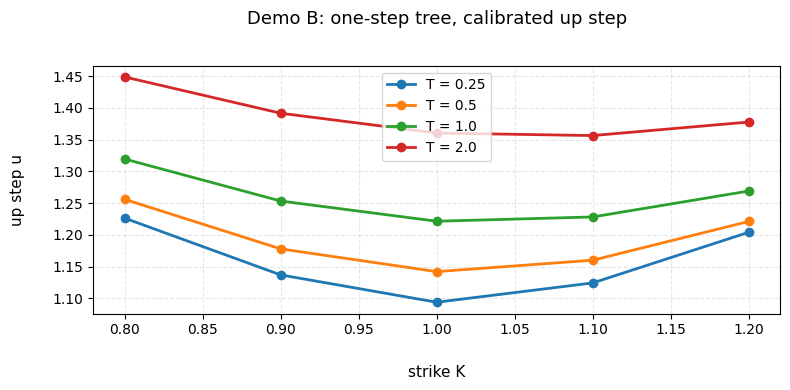

In [4]:
common = {"grid": True, "title_fontsize": 13, "label_fontsize": 11, "legend_fontsize": 10,
          "linewidth": 2, "markers": "o", "hline": None}
names = [f"T = {T}" for T in expiries]
my_plotter(strikes, u_table, names=names,
           layout={**common, "title": "Demo B: one-step tree, calibrated up step",
                   "x_label": "strike K", "y_label": "up step u", "legend_loc": "upper center"});

**Plot 2**: one-step tree volatility against $K$, one line per $T$

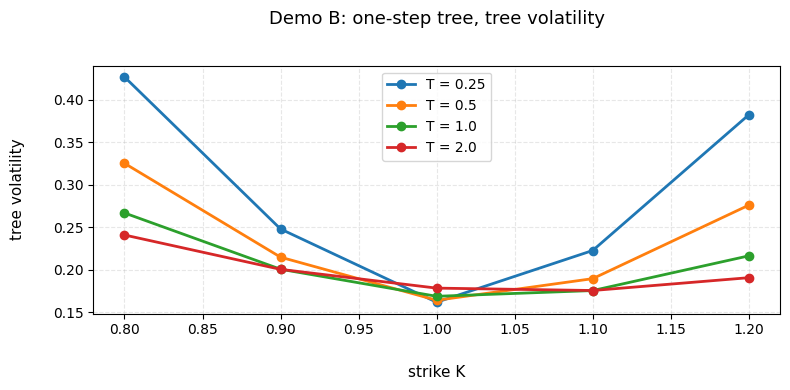

In [5]:
my_plotter(strikes, vol_table, names=names,
           layout={**common, "title": "Demo B: one-step tree, tree volatility",
                   "x_label": "strike K", "y_label": "tree volatility"});

**Result**: no `ValueError` (every price is attainable) and $u$ = `brentq` up to $10^{-9}$; $u$ grows with $T$; the tree volatility is not flat in $K$ (smallest near the money, larger in the wings): one step cannot copy the Black-Scholes distribution, so each strike needs its own $u$.